In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
MARKET = "EU"
TEST_START = "2022-01-01"
FUELS = {"EU_Clean_Spark_Spread": "Gas", "EU_Clean_Dark_Spread": "Coal", "EU_Clean_Gasoil_Spread": "Oil"}
AR_COLOR = "#e87ba4"

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "grid.color": "#e1e0d9", "axes.titlelocation": "left", "axes.titlesize": 12, "legend.frameon": False,
})

In [3]:
spreads = pd.read_csv("../3_Compute/eu_spreads.csv", index_col="date", parse_dates=True).sort_index()
spreads.tail()

,EU_Clean_Spark_Spread,EU_Clean_Dark_Spread,EU_Clean_Gasoil_Spread
date,,,
2026-11-03,17.098902,93.426052,-142.436978
2026-11-04,25.259765,95.404707,-125.986309
2026-11-05,23.336863,99.598096,-122.875018
2026-11-06,30.839804,99.358830,-128.083017
2026-11-09,21.120980,84.137340,-135.505088


In [4]:
pd.DataFrame({
    f"Lag {k}": spreads.apply(lambda x: x.autocorr(k)) for k in (1, 5, 20)
}).rename(index=FUELS).round(3)

,Lag 1,Lag 5,Lag 20
Gas,0.927,0.706,0.479
Coal,0.981,0.895,0.622
Oil,0.986,0.928,0.692


In [5]:
def fit_ar1(history):
    return {col: np.polyfit(history[col].iloc[:-1], history[col].iloc[1:], 1) for col in history}


def predict_ar1(coefs, today):
    return pd.DataFrame({col: phi * today[col] + c for col, (phi, c) in coefs.items()})

In [6]:
target = spreads.shift(-1)
test_days = spreads.index[(spreads.index >= TEST_START) & target.notna().all(axis=1)]
months = pd.date_range(TEST_START, test_days[-1] + pd.offsets.MonthBegin(), freq="MS")

predictions = []
for start, end in zip(months[:-1], months[1:]):
    coefs = fit_ar1(spreads[spreads.index < start])
    days = test_days[(test_days >= start) & (test_days < end)]
    predictions.append(predict_ar1(coefs, spreads.loc[days]))

pred = pd.concat(predictions)
actual = target.loc[pred.index]
print(f"Test: {pred.index[0].date()} -> {pred.index[-1].date()}, {len(pred)} days, {len(months) - 1} monthly refits")

Test: 2022-01-03 -> 2026-11-06, 1264 days, 59 monthly refits


In [7]:
errors = pred - actual
naive = spreads.loc[pred.index]

pd.DataFrame({
    "MAE (€/MWh)": errors.abs().mean(),
    "RMSE (€/MWh)": np.sqrt((errors ** 2).mean()),
    "Naive RMSE (tomorrow = today)": np.sqrt(((naive - actual) ** 2).mean()),
}).rename(index=FUELS).round(2)

,MAE (€/MWh),RMSE (€/MWh),Naive RMSE (tomorrow = today)
Gas,5.38,10.90,11.08
Coal,4.05,9.62,9.61
Oil,6.39,12.00,12.01


In [8]:
print(f"Best fuel (highest next-day spread) picked right: {(pred.idxmax(axis=1) == actual.idxmax(axis=1)).mean():.1%} of test days")

Best fuel (highest next-day spread) picked right: 96.8% of test days


In [9]:
coefs = fit_ar1(spreads)
params = pd.DataFrame(coefs, index=["phi", "c"]).T.rename(index=FUELS)
params["Long-run mean (€/MWh)"] = params["c"] / (1 - params["phi"])
params.round(3)

,phi,c,Long-run mean (€/MWh)
Gas,0.927,-1.124,-15.494
Coal,0.982,-0.061,-3.398
Oil,0.986,-1.534,-109.876


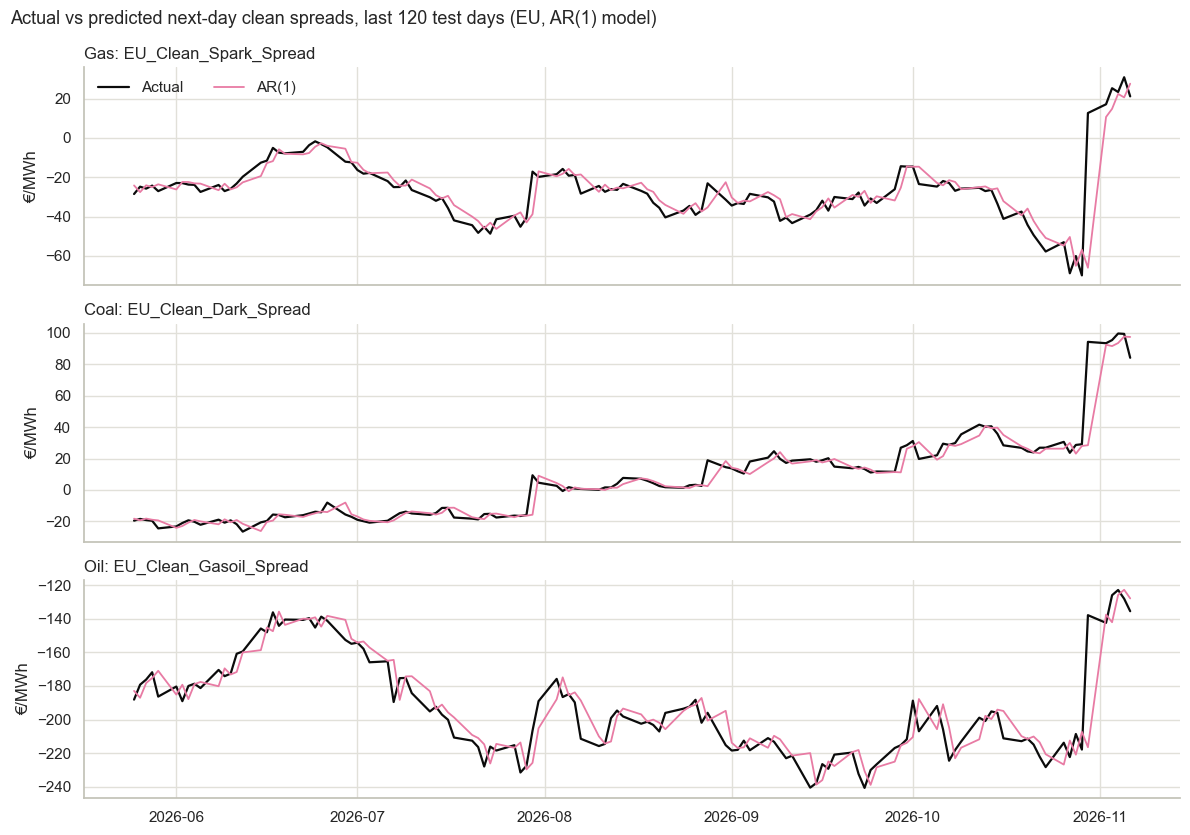

In [10]:
window = pred.index[-120:]

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for ax, (col, fuel) in zip(axes, FUELS.items()):
    ax.plot(window, actual.loc[window, col], color="#0b0b0b", lw=1.6, label="Actual")
    ax.plot(window, pred.loc[window, col], color=AR_COLOR, lw=1.3, label="AR(1)")
    ax.set_title(f"{fuel}: {col}")
    ax.set_ylabel("€/MWh")
axes[0].legend(loc="upper left", ncols=2)
fig.suptitle(f"Actual vs predicted next-day clean spreads, last 120 test days ({MARKET}, AR(1) model)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

In [11]:
next_day = spreads.index[-1] + pd.offsets.BDay(1)
forecast = predict_ar1(coefs, spreads.iloc[[-1]]).iloc[0].rename(index=FUELS).rename("Forecast (€/MWh)")

print(f"Forecast for {next_day.date()} using data up to {spreads.index[-1].date()}")
print(f"Best fuel: {forecast.idxmax()}")
forecast.round(2)

Forecast for 2026-11-10 using data up to 2026-11-09
Best fuel: Coal


Gas      18.47
Coal     82.56
Oil    -135.15
Name: Forecast (€/MWh), dtype: float64